## Testes do fit para várias frações de gordura no fígado

In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

In [2]:
# FUNÇÃO PARA O CÁLCULO DA FRAÇÃO DE GORDURA
def dixon(s23,s46):
    rw = (s46 + s23)/2
    rf = (s46 - s23)/2         
    ff = rf / (rf + rw)    
    return(ff)

In [3]:
magField = 3.0      # tesla
hydroGyro = 42.57e6 # Hz/T
T2star = [0.030, 0.040, 0.051, 0.052, 0.062, 0.083, 0.023]
Fppmn = [5.3, 4.2, 2.75, 2.1, 1.3, 0.9, 4.7]

# FUNÇÃO DO FIT
def fit1(x, a, b, c, d, e, f, g):
    return np.absolute(a*np.exp(-x/T2star[0])*np.exp((2.*np.pi*1j*Fppmn[0]*magField*hydroGyro/1e6)*x) + 
                       b*np.exp(-x/T2star[1])*np.exp((2.*np.pi*1j*Fppmn[1]*magField*hydroGyro/1e6)*x) + 
                       c*np.exp(-x/T2star[2])*np.exp((2.*np.pi*1j*Fppmn[2]*magField*hydroGyro/1e6)*x) + 
                       d*np.exp(-x/T2star[3])*np.exp((2.*np.pi*1j*Fppmn[3]*magField*hydroGyro/1e6)*x) + 
                       e*np.exp(-x/T2star[4])*np.exp((2.*np.pi*1j*Fppmn[4]*magField*hydroGyro/1e6)*x) +
                       f*np.exp(-x/T2star[5])*np.exp((2.*np.pi*1j*Fppmn[5]*magField*hydroGyro/1e6)*x) +
                       g*np.exp(-x/T2star[6])*np.exp((2.*np.pi*1j*Fppmn[6]*magField*hydroGyro/1e6)*x))

## 2% de gordura

In [4]:
# GERANDO OS DADOS PARA 2% DE GORDURA

fatPercent = 0.02

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

In [5]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])
# VALORES INICIAIS
p0 = rho
# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[  5.19375869e-05   5.53455170e-05   1.49435658e-06   1.16712199e-05
   2.69460651e-05   1.48972441e-05   4.99849991e-06]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


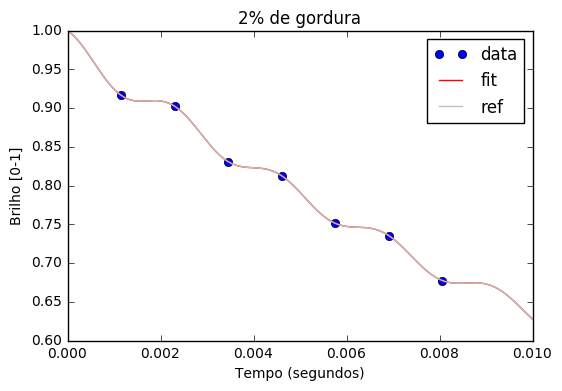

In [6]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0)

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('2% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

## 5% de gordura 

In [7]:
# GERANDO OS DADOS PARA 5% DE GORDURA

fatPercent = 0.05

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[  1.34147669e-04   1.44575944e-04   3.90506443e-06   2.92871405e-05
   6.78316160e-05   3.81955561e-05   1.41577244e-05]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


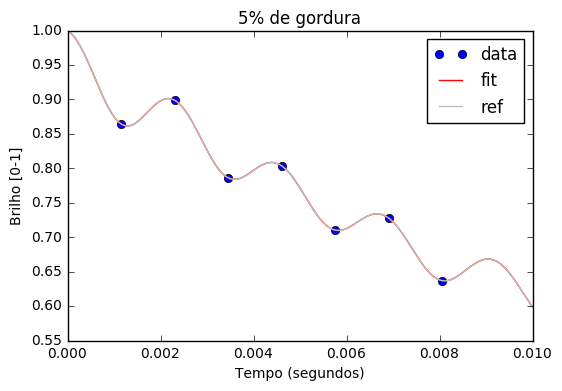

In [8]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0) 

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('5% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

## 10% de gordura 

In [9]:
# GERANDO OS DADOS PARA 10% DE GORDURA

fatPercent = 0.1

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[  2.84459497e-04   3.12116770e-04   8.66001263e-06   5.92377985e-05
   1.37036030e-04   7.92839029e-05   3.44656357e-05]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


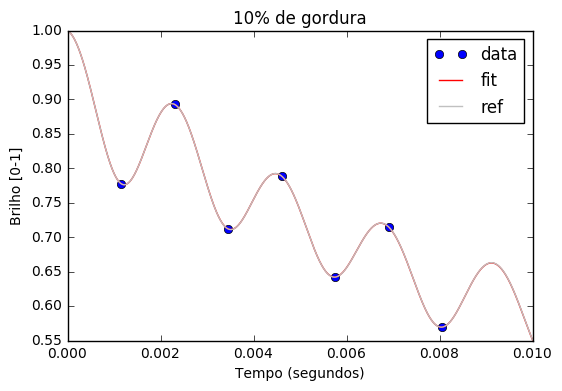

In [10]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0) 

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('10% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

## 20% de gordura 

In [11]:
# GERANDO OS DADOS PARA 20% DE GORDURA

fatPercent = 0.2

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[  6.59696717e-04   7.45734853e-04   2.50140940e-05   1.23909863e-04
   2.77613462e-04   1.66347947e-04   1.01321227e-04]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


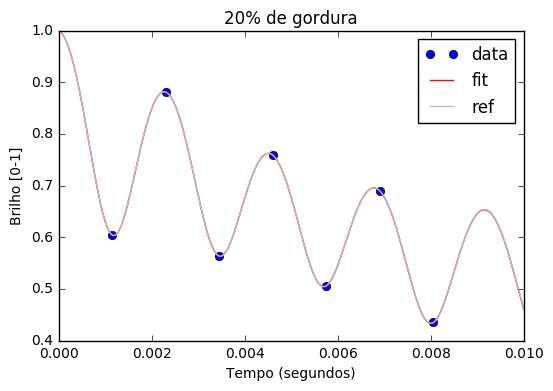

In [12]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0) 

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('20% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

## 30% de gordura

In [13]:
# GERANDO OS DADOS PARA 30% DE GORDURA

fatPercent = 0.3

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[  1.25789637e-03   1.43967773e-03   7.47137244e-05   2.04706632e-04
   4.13945109e-04   2.42087593e-04   2.36550394e-04]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


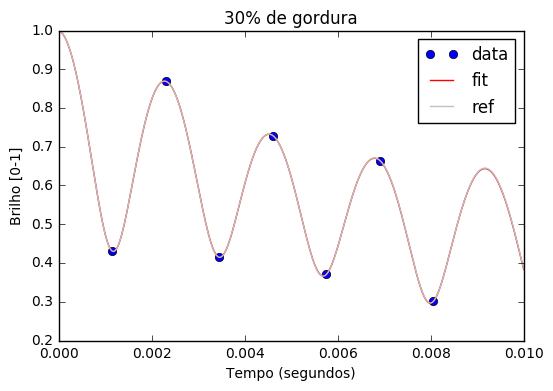

In [14]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0) 

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('30% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

## 40% de gordura

In [15]:
# GERANDO OS DADOS PARA 40% DE GORDURA

fatPercent = 0.4

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[ 0.00302258  0.00328546  0.00038686  0.00032455  0.00053925  0.00021774
  0.00067228]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


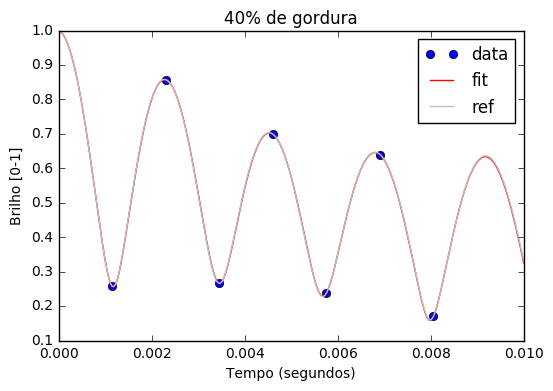

In [16]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0) 

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('40% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

## 50% de gordura 

In [17]:
# GERANDO OS DADOS PARA 50% DE GORDURA

fatPercent = 0.5

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[ 0.01001119  0.0075594   0.00262157  0.0003509   0.00041124  0.00021814
  0.00110701]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


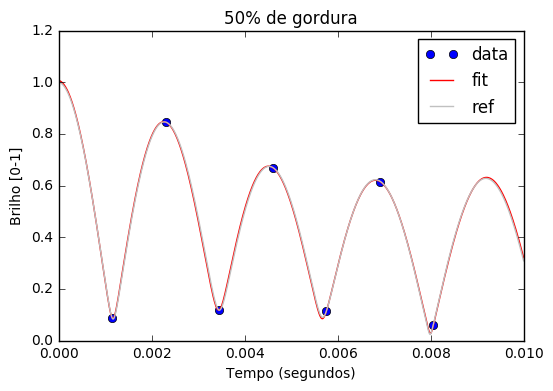

In [18]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0) 

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('50% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

## 60% de gordura

In [19]:
# GERANDO OS DADOS PARA 60% DE GORDURA

fatPercent = 0.6

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal)

Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:
[ 0.0282      0.01716908  0.0036      0.05726124  0.09292039  0.02896192
  0.06565027]


C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


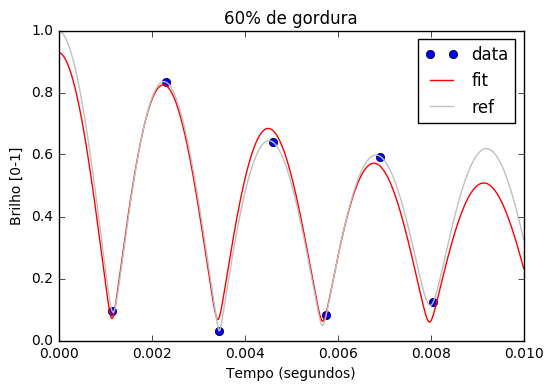

In [20]:
# "FITANDO OS DADOS"
popt, pcov = curve_fit(fit1, t,  Sfinal, bounds=bd, p0=p0) 

print('Diferença entre o chute inicial (rho) e os parâmetros encontrados no fit:')
print(np.abs(rho-popt))

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal,'bo', label='data')
plt.plot(x, fit1(x,*popt), 'r-', label='fit')
plt.plot(x, fit1(x,*rho), '#C0C0C0', label='ref')

# PLOT (BONITO)?
plt.title('60% de gordura')
plt.legend(loc='best')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')

In [21]:
#standard error of estimate (s)
def s_measure(observed_score, predicted_score, n_scores):
    s = np.sqrt(np.sum(np.square(observed_score-predicted_score))/(n_scores))
    return s